In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [30]:
data_dir = Path("../data/raw")

files = sorted(data_dir.glob("gpg_*.csv"))

dataframes = []

for file in files:
    df = pd.read_csv(file)
    df["report_year"] = int(file.stem.split("_")[1])
    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)

## distribution of median gender pay gap

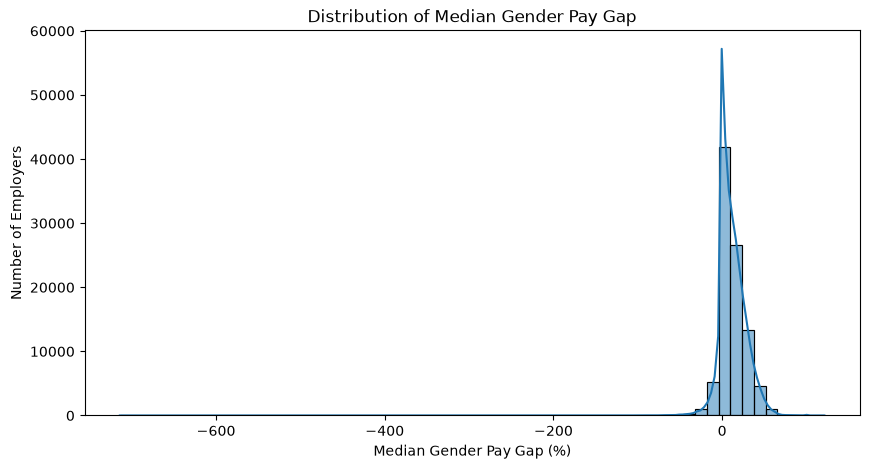

In [31]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["DiffMedianHourlyPercent"],
    bins=60,
    kde=True
)

plt.title("Distribution of Median Gender Pay Gap")
plt.xlabel("Median Gender Pay Gap (%)")
plt.ylabel("Number of Employers")
plt.show()

In [32]:
data["DiffMedianHourlyPercent"].describe()

count    94205.000000
mean        11.815428
std         15.876093
min       -714.000000
25%          0.900000
50%          9.200000
75%         20.800000
max        121.200000
Name: DiffMedianHourlyPercent, dtype: float64

## inspect extreme observations

In [33]:
print("Lowest 10 values:")

display(
    data.nsmallest(10, "DiffMedianHourlyPercent")[
        ["EmployerName", "report_year", "DiffMedianHourlyPercent"]
    ]
)

print("Highest 10 values:")

display(
    data.nlargest(10, "DiffMedianHourlyPercent")[
        ["EmployerName", "report_year", "DiffMedianHourlyPercent"]
    ]
)

Lowest 10 values:


,EmployerName,report_year,DiffMedianHourlyPercent
67765,PATTONAIR (DERBY) LIMITED,2023,-714.00
39517,ANKH CONCEPTS HOSPITALITY MANAGEMENT LIMITED,2021,-499.50
35009,NSS CLEANING LIMITED,2020,-487.20
29190,AUTO-SLEEPERS GROUP LIMITED,2020,-220.30
29191,AUTO-SLEEPERS INVESTMENTS LIMITED,2020,-220.30
839,BAR 2010 LIMITED,2017,-196.50
4497,INBRELLA LIMITED,2017,-164.00
86522,FIRMENICH UK LIMITED,2025,-156.14
53169,FORTEL SERVICES LIMITED,2022,-153.80
23187,DONALDSON TIMBER ENGINEERING LIMITED,2019,-134.00


Highest 10 values:


,EmployerName,report_year,DiffMedianHourlyPercent
8053,Shrewsbury Academies Trust,2017,121.2
11204,ASH & LACY FINISHES LIMITED,2018,100.0
19538,T. CLASS SECURITY LIMITED,2018,100.0
27250,T. CLASS SECURITY LIMITED,2019,100.0
29457,BEERE ELECTRICAL SERVICES LIMITED,2020,100.0
32540,HARVEY NICHOLS (OWN BRAND) STORES LIMITED,2020,100.0
32544,HARVEY NICHOLS RESTAURANTS LIMITED,2020,100.0
33185,J.C.B.EARTHMOVERS LIMITED,2020,100.0
33198,J5C MANAGEMENT LIMITED,2020,100.0
33245,JCB COMPACT PRODUCTS LIMITED,2020,100.0


## summary statistics

In [34]:
# Summary statistics
print("Median Gender Pay Gap Statistics")
display(data["DiffMedianHourlyPercent"].describe())

# Year-wise average and median
yearly_summary = (
    data.groupby("report_year")["DiffMedianHourlyPercent"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(yearly_summary)

Median Gender Pay Gap Statistics


count    94205.000000
mean        11.815428
std         15.876093
min       -714.000000
25%          0.900000
50%          9.200000
75%         20.800000
max        121.200000
Name: DiffMedianHourlyPercent, dtype: float64

,count,mean,median,std
report_year,,,,
2017,10569,11.80,9.30,15.83
2018,10838,11.91,9.50,15.52
2019,7055,12.78,10.40,15.37
2020,10583,12.45,10.00,17.66
2021,10567,12.18,9.70,16.83
2022,10908,11.95,9.17,15.26
2023,11169,11.47,8.91,16.47
2024,11315,11.21,8.40,14.77
2025,11201,11.02,8.00,14.82


## ANNUAL PAY GAP TREND 

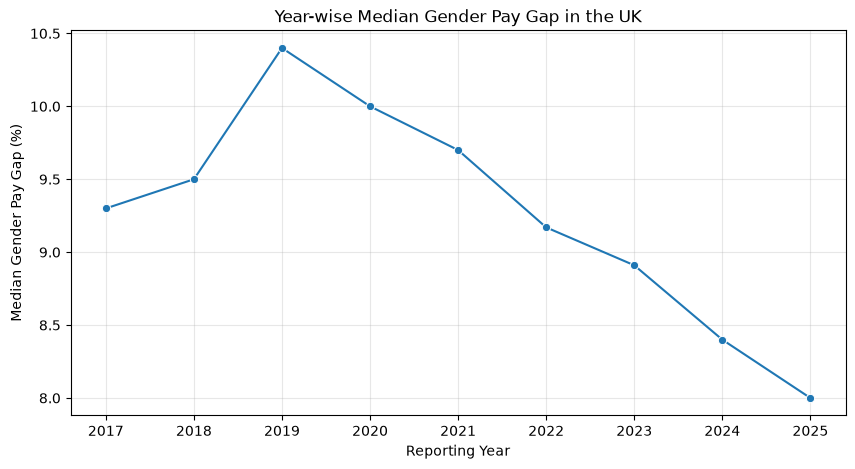

In [35]:
yearly_trend = (
    data.groupby("report_year")["DiffMedianHourlyPercent"]
    .median()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_trend,
    x="report_year",
    y="DiffMedianHourlyPercent",
    marker="o"
)

plt.title("Year-wise Median Gender Pay Gap in the UK")
plt.xlabel("Reporting Year")
plt.ylabel("Median Gender Pay Gap (%)")
plt.xticks(yearly_trend["report_year"])
plt.grid(True, alpha=0.3)
plt.show()

In [36]:
yearly_trend.to_csv(
    "../outputs/yearly_gender_pay_gap_trend.csv",
    index=False
)

## classify employers by sector

In [37]:
import re
import pandas as pd

def classify_sector(sic):
    if pd.isna(sic) or str(sic).strip() == "":
        return "Unknown"

    codes = re.findall(r"\d{4,5}", str(sic))

    if not codes:
        return "Unknown"

    if any(
        code.startswith(("14", "4771", "4772")) or code == "46420"
        for code in codes
    ):
        return "Fashion"

    if any(code.startswith("47") for code in codes):
        return "Other Retail"

    return "Other"


data["sector"] = data["SicCodes"].apply(classify_sector)

## check classification

In [38]:
print("Sector distribution:")
display(data["sector"].value_counts())

print("\nSector distribution by reporting year:")
display(
    pd.crosstab(data["report_year"], data["sector"])
)

Sector distribution:


sector
Other           82322
Unknown          7619
Other Retail     3108
Fashion          1156
Name: count, dtype: int64


Sector distribution by reporting year:


sector,Fashion,Other,Other Retail,Unknown
report_year,,,,
2017,159,9109,383,918
2018,156,9622,382,678
2019,74,6259,199,523
2020,135,9346,347,755
2021,128,9256,350,833
2022,127,9522,361,898
2023,125,9729,359,956
2024,126,9811,370,1008
2025,126,9668,357,1050


In [39]:
display(data["sector"].value_counts())

sector
Other           82322
Unknown          7619
Other Retail     3108
Fashion          1156
Name: count, dtype: int64

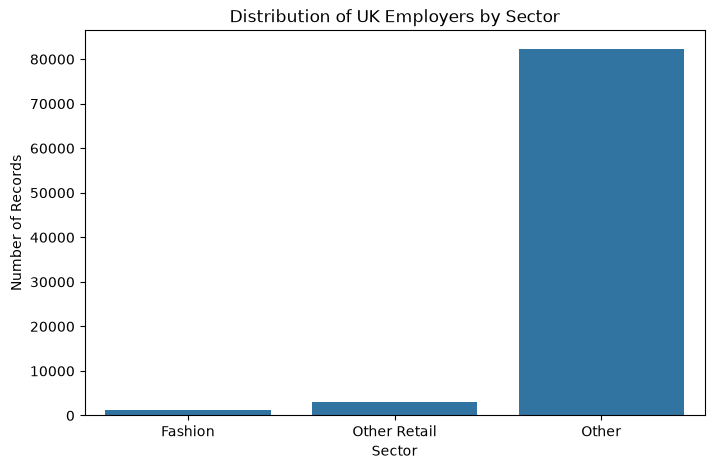

In [40]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="sector",
    order=["Fashion", "Other Retail", "Other"]
)

plt.title("Distribution of UK Employers by Sector")
plt.xlabel("Sector")
plt.ylabel("Number of Records")
plt.show()

## sector wise pay gap analysis

In [41]:
sector_summary = (
    data.groupby("sector")["DiffMedianHourlyPercent"]
    .agg(
        employers="count",
        average_gap="mean",
        median_gap="median",
        standard_deviation="std"
    )
    .round(2)
)

display(sector_summary)

,employers,average_gap,median_gap,standard_deviation
sector,,,,
Fashion,1156,8.23,4.30,13.40
Other,82322,11.70,9.14,15.98
Other Retail,3108,6.30,3.40,11.28
Unknown,7619,15.86,14.00,15.69


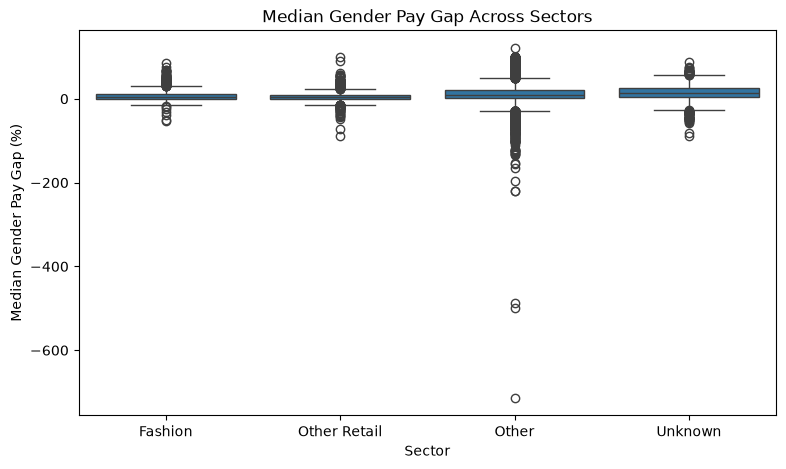

In [42]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="sector",
    y="DiffMedianHourlyPercent",
    order=["Fashion", "Other Retail", "Other", "Unknown"]
)

plt.title("Median Gender Pay Gap Across Sectors")
plt.xlabel("Sector")
plt.ylabel("Median Gender Pay Gap (%)")
plt.show()